# DL(5): vehicle speed from dashcam images (Comma2k19)
**Paratat Udomkiat**

Predict the car's speed (km/h) for every frame from the camera images only (no GPS, wheel-speed or IMU input).
Development used 3-fold drive-level cross-validation (CV) on the 68 train + validation drives; the 8 test drives
(1,200 frames each, 20 Hz) were used only for evaluation.

**Submitted result (test #12): overall test RMSE 1.212 km/h; average of the 8 per-drive RMSEs 1.103 km/h.**

Pipeline:
1. **Data**: frame index, 3 CV folds, two image caches: a 192 x 96 bird's-eye (top-down) warp and a 144 x 256 front view.
2. **Top-down branch**: ConvNeXt-Tiny (ImageNet-1k) on 17 consecutive RGB frames (51 x 192 x 96), speed augmentation;
   12 models (6 trained on all 68 drives + 6 CV-fold models).
3. **Front-view branch**: ConvNeXt-Nano (ImageNet-12k) on 5 greyscale frames + 5 frame differences (10 x 144 x 256);
   5 models (2 all-data seeds + 3 CV-fold models).
4. **Selection**: blend, smoothing window and bias offset chosen by nested cross-fit on out-of-fold predictions.
5. **Final test evaluation**: temporal test-time augmentation, speed-dependent blend, 41-frame smoothing, offset.

**What runs in this notebook.** Each `%%writefile` cell writes one source file into `src/`; this is the code that
produced the final model. Preprocessing, training and test-time augmentation were run earlier as these scripts / one-cell
notebooks (more than a day of GPU time on an RTX 4060 Laptop GPU); their cells are skipped unless `RUN_HEAVY = True` and
the later cells reuse the checkpoints and prediction files in `outputs/`. Sections 4-6 are executed here.

Libraries: PyTorch 2 + torchvision (ConvNeXt-Tiny ImageNet weights), timm (`convnext_nano.in12k_ft_in1k` weights),
OpenCV, pandas, scikit-learn.

In [1]:
import os
import sys
import subprocess
import time

PROJECT = os.path.abspath('.')   # project folder: raw data, processed_data/ (caches) and outputs/ (checkpoints, predictions)
os.makedirs('src', exist_ok=True)
RUN_HEAVY = False                # True re-runs preprocessing, training and test-time augmentation


def sh(cmd, heavy=True, env=None):
    """Run a src/ script from the project folder; heavy steps are skipped unless RUN_HEAVY is set."""
    if heavy and not RUN_HEAVY:
        print('skipped (RUN_HEAVY = False):', cmd)
        return
    t0 = time.time()
    r = subprocess.run(f'"{sys.executable}" {cmd}', shell=True, cwd=PROJECT, env=dict(os.environ, **(env or {})),
                       capture_output=True, text=True)
    print(r.stdout)
    if r.returncode:
        print(r.stderr[-4000:])
        raise RuntimeError(cmd)
    print(f'[{cmd}: {time.time() - t0:.0f} s]')

## 1. Data preparation
* `preprocess.py` reads every `labels.csv` (speed = column 5, `car_speed_km_h`) and builds the frame index
  `master_index.csv` (it also writes the 128 x 384 crops used by the first ResNet-18 runs).
* `build_memmap_index.py` adds `memmap_idx`, the row of each frame in the image caches (`master_index_memmap.csv`).
* `Make_CV_Folds.py` splits the 68 train + validation drives into 3 folds, stratified by mean speed (`master_index_cv.csv`).
* `precompute_topdown.py`: road trapezoid of the 1164 x 874 frame warped to a 192 x 96 bird's-eye view (uint8 memmap).
* `precompute_fullimage.py`: the whole frame resized to 144 x 256 (uint8 memmap), used by the front-view branch.

In [2]:
%%writefile src/preprocess.py
import os
import cv2
import pandas as pd
import zipfile
from tqdm import tqdm

BASE = os.path.abspath('.')  # repository root (run scripts from here)
RAW_DATA_DIR = os.path.join(BASE, "Comma_2k19_Driving_Dataset", "Comma_2k19_Driving_Dataset")
OUTPUT_DIR = os.path.join(BASE, "processed_data")
ZIP_NAME = os.path.join(BASE, "dataset_128x384.zip")

os.makedirs(OUTPUT_DIR, exist_ok=True)
master_records = []

for split in ["Training", "Validation", "Testing"]:
    split_path = os.path.join(RAW_DATA_DIR, split)
    if not os.path.exists(split_path): continue

    for set_folder in os.listdir(split_path):
        set_path = os.path.join(split_path, set_folder)
        labels_csv = os.path.join(set_path, "labels.csv")

        if not os.path.exists(labels_csv): continue

        df = pd.read_csv(labels_csv)

        for _, row in df.iterrows():
            speed = row.get("car_speed_km_h")
            if pd.isna(speed) or speed == "":
                continue

            img_name = row["filename"]
            img_path = os.path.join(set_path, img_name)

            if not os.path.exists(img_path): continue

            img = cv2.imread(img_path)
            cropped = img[280:650, :]
            resized = cv2.resize(cropped, (384, 128), interpolation=cv2.INTER_AREA)

            new_filename = f"{split}_{set_folder}_{img_name}"
            cv2.imwrite(os.path.join(OUTPUT_DIR, new_filename), resized)

            master_records.append({
                "split": split,
                "set_id": f"{split}_{set_folder}",
                "frame_id": int(row["frame"]), # Using true frame column
                "filename": new_filename,
                "speed": float(speed)
            })

master_df = pd.DataFrame(master_records)
master_df = master_df.sort_values(by=["set_id", "frame_id"]).reset_index(drop=True)
master_df.to_csv(os.path.join(OUTPUT_DIR, "master_index.csv"), index=False)

print("Packing uncompressed ZIP (ZIP_STORED)...")
with zipfile.ZipFile(ZIP_NAME, 'w', zipfile.ZIP_STORED) as zipf:
    for root, dirs, files in os.walk(OUTPUT_DIR):
        for file in tqdm(files):
            zipf.write(os.path.join(root, file), file)
print(f"Done. Upload {ZIP_NAME} to Google Drive.")

Overwriting src/preprocess.py


In [3]:
%%writefile src/build_memmap_index.py
# Row index of every frame in the image caches (memmap_idx). From RunB_Local.ipynb (cells 1-2); the cell also builds the
# 128 x 384 RGB memmap of the first ResNet-18 runs. The final models only use master_index_memmap.csv.
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

BASE_DIR = os.path.abspath('.')
DATA_DIR = os.path.join(BASE_DIR, 'processed_data')
CSV_INDEX = os.path.join(DATA_DIR, 'master_index.csv')
MEMMAP_PATH = os.path.join(DATA_DIR, 'dataset_memmap.dat')
MEMMAP_CSV = os.path.join(DATA_DIR, 'master_index_memmap.csv')

# --- Cell 2: Builds the uint8 memmap using PIL if missing or invalid ---
df = pd.read_csv(CSV_INDEX)
N = len(df)
expected_shape = (N, 128, 384, 3)
expected_bytes = N * 128 * 384 * 3

needs_build = True
if os.path.exists(MEMMAP_PATH) and os.path.exists(MEMMAP_CSV):
    if os.path.getsize(MEMMAP_PATH) == expected_bytes:
        print("Valid memmap found. Skipping generation.")
        needs_build = False

if needs_build:
    print(f"Allocating memmap of shape {expected_shape} (~{expected_bytes/1e9:.2f} GB)...")
    mm = np.memmap(MEMMAP_PATH, dtype='uint8', mode='w+', shape=expected_shape)

    for i, row in tqdm(df.iterrows(), total=N, desc="Decoding JPEGs (PIL)"):
        img_path = os.path.join(DATA_DIR, row['filename'])
        img = Image.open(img_path).convert('RGB')
        mm[i] = np.array(img, dtype='uint8')

    mm.flush()
    df['memmap_idx'] = df.index
    df.to_csv(MEMMAP_CSV, index=False)
    print("Memmap successfully created.")

Overwriting src/build_memmap_index.py


In [4]:
%%writefile src/Make_CV_Folds.py
# --- Fold Generation Script (Run Once) ---
import pandas as pd
from sklearn.model_selection import StratifiedKFold

CSV_INDEX = 'processed_data/master_index_memmap.csv'
OUT_CSV = 'processed_data/master_index_cv.csv'
NUM_FOLDS = 3

df = pd.read_csv(CSV_INDEX)
df_trainval = df[df['split'].isin(['Training', 'Validation'])]
stats = df_trainval.groupby('set_id')['speed'].mean().reset_index()

# Use quantiles (q=3) to guarantee perfectly equal bins, preventing StratifiedKFold from crashing
stats['speed_cat'] = pd.qcut(stats['speed'], q=3, labels=['Low', 'Medium', 'High'])

skf = StratifiedKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=42)
stats['cv_fold'] = -1

for fold, (_, val_idx) in enumerate(skf.split(stats['set_id'], stats['speed_cat'])):
    stats.loc[val_idx, 'cv_fold'] = fold

fold_map = dict(zip(stats['set_id'], stats['cv_fold']))
df['cv_fold'] = df['set_id'].map(fold_map).fillna(-1).astype(int)

df.to_csv(OUT_CSV, index=False)
print(f"Stratified CV splits saved to {OUT_CSV}")
print("\nDrive Counts per Fold & Speed Tier:")
print(stats.groupby(['cv_fold', 'speed_cat'], observed=False).size())

Overwriting src/Make_CV_Folds.py


In [5]:
%%writefile src/precompute_topdown.py
import os
import cv2
import numpy as np
import pandas as pd
import concurrent.futures

BASE_DIR = os.path.abspath('.')
DATA_DIR = os.path.join(BASE_DIR, 'processed_data')
CSV_PATH = os.path.join(DATA_DIR, 'master_index_memmap.csv')  # original Training/Validation/Testing folders, same row order as memmap_idx
RAW_DIR = os.path.join(BASE_DIR, 'Comma_2k19_Driving_Dataset', 'Comma_2k19_Driving_Dataset')
TOPDOWN_MEMMAP_PATH = os.path.join(DATA_DIR, 'topdown_memmap.dat')

# Dimensions: H=192, W=96
H_NEW, W_NEW = 192, 96
TOTAL_FRAMES = 91200 # Update if your total frame count differs

# Warp at 4x width first, then downsample with INTER_AREA to avoid aliasing of the road texture
W_BIG = W_NEW * 4

# Compute Homography Matrix once
src_pts = np.array([[455, 480], [715, 480], [1164, 650], [0, 650]], dtype=np.float32)
dst_pts = np.array([[0, 0], [W_BIG, 0], [W_BIG, H_NEW], [0, H_NEW]], dtype=np.float32)
M = cv2.getPerspectiveTransform(src_pts, dst_pts)

def get_raw_image(row):
    # set_id = "<Split>_Comma_2k19_<N>", filename = "<set_id>_image<N>_<frame>.jpg"
    split, folder = row['set_id'].split('_', 1)
    raw_name = row['filename'][len(row['set_id']) + 1:]
    raw_path = os.path.join(RAW_DIR, split, folder, raw_name)
    img = cv2.imread(raw_path)
    if img is None:
        raise FileNotFoundError(raw_path)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def process_row(idx_and_row):
    idx, row = idx_and_row
    img = get_raw_image(row)

    # Warp to Bird's Eye View
    warped = cv2.warpPerspective(img, M, (W_BIG, H_NEW), flags=cv2.INTER_LINEAR)
    warped = cv2.resize(warped, (W_NEW, H_NEW), interpolation=cv2.INTER_AREA)
    return row['memmap_idx'], warped

if __name__ == '__main__':
    df = pd.read_csv(CSV_PATH)

    # Pre-allocate memmap
    memmap = np.memmap(TOPDOWN_MEMMAP_PATH, dtype='uint8', mode='w+',
                       shape=(TOTAL_FRAMES, H_NEW, W_NEW, 3))

    print(f"Warping {len(df)} frames to top-down view...")

    # CPU-bound, so ProcessPool is ideal
    with concurrent.futures.ProcessPoolExecutor(max_workers=os.cpu_count()) as executor:
        results = executor.map(process_row, df.iterrows(), chunksize=100)

        for i, (memmap_idx, warped_img) in enumerate(results):
            memmap[memmap_idx] = warped_img
            if (i + 1) % 5000 == 0:
                print(f"Processed {i + 1}/{len(df)} frames...")

    memmap.flush()
    print(f"Top-down precomputation complete. Saved to {TOPDOWN_MEMMAP_PATH}")

Overwriting src/precompute_topdown.py


In [6]:
%%writefile src/precompute_fullimage.py
import os
import cv2
import numpy as np
import pandas as pd
import concurrent.futures

BASE_DIR = os.path.abspath('.')
DATA_DIR = os.path.join(BASE_DIR, 'processed_data')
CSV_PATH = os.path.join(DATA_DIR, 'master_index_memmap.csv')  # original Training/Validation/Testing folders, same row order as memmap_idx
RAW_DIR = os.path.join(BASE_DIR, 'Comma_2k19_Driving_Dataset', 'Comma_2k19_Driving_Dataset')
FULLIMG_MEMMAP_PATH = os.path.join(DATA_DIR, 'fullimage_memmap.dat')

H_NEW, W_NEW = 144, 256
TOTAL_FRAMES = 91200

def get_raw_image(row):
    # set_id = "<Split>_Comma_2k19_<N>", filename = "<set_id>_image<N>_<frame>.jpg"
    split, folder = row['set_id'].split('_', 1)
    raw_name = row['filename'][len(row['set_id']) + 1:]
    raw_path = os.path.join(RAW_DIR, split, folder, raw_name)
    img = cv2.imread(raw_path)
    if img is None:
        raise FileNotFoundError(raw_path)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def process_row(idx_and_row):
    idx, row = idx_and_row
    img = get_raw_image(row)

    # 1. Resize to 256x192 preserving texture
    resized = cv2.resize(img, (256, 192), interpolation=cv2.INTER_AREA)
    
    # 2. Crop top 75% (Rows 0 through 143) to remove dashboard/hood
    cropped = resized[0:144, :, :]
    
    return row['memmap_idx'], cropped

if __name__ == '__main__':
    df = pd.read_csv(CSV_PATH)

    # Pre-allocate memmap
    memmap = np.memmap(FULLIMG_MEMMAP_PATH, dtype='uint8', mode='w+',
                       shape=(TOTAL_FRAMES, H_NEW, W_NEW, 3))

    print(f"Resizing and cropping {len(df)} frames for full-image view...")

    # CPU-bound, so ProcessPool is ideal
    with concurrent.futures.ProcessPoolExecutor(max_workers=os.cpu_count()) as executor:
        results = executor.map(process_row, df.iterrows(), chunksize=100)

        for i, (memmap_idx, processed_img) in enumerate(results):
            memmap[memmap_idx] = processed_img
            if (i + 1) % 5000 == 0:
                print(f"Processed {i + 1}/{len(df)} frames...")

    memmap.flush()
    print(f"Full-image precomputation complete. Saved to {FULLIMG_MEMMAP_PATH}")

Overwriting src/precompute_fullimage.py


In [7]:
for script in ('preprocess.py', 'build_memmap_index.py', 'Make_CV_Folds.py', 'precompute_topdown.py', 'precompute_fullimage.py'):
    sh(f'src/{script}')

skipped (RUN_HEAVY = False): src/preprocess.py
skipped (RUN_HEAVY = False): src/build_memmap_index.py
skipped (RUN_HEAVY = False): src/Make_CV_Folds.py
skipped (RUN_HEAVY = False): src/precompute_topdown.py
skipped (RUN_HEAVY = False): src/precompute_fullimage.py


## 2. Top-down branch: ConvNeXt-Tiny on 17 bird's-eye frames
* Input: 17 consecutive RGB frames t-8 ... t+8 (0.85 s), stacked on the channel axis -> **51 x 192 x 96**, ImageNet
  normalisation per frame. The stem convolution is widened to 51 channels (pretrained RGB weights repeated / 17).
* Training: MSE on speed / 100, AdamW (lr 1e-4, weight decay 1e-2), cosine schedule, 15 epochs, batch 64, mixed precision.
  Augmentation: horizontal flip, colour jitter (same for all frames) and **speed augmentation**: with p = 0.5 the window
  takes every 2nd frame and the label is doubled (only if 2 x speed <= 135 km/h). Variant **SZ** adds random zoom 0.15.
* Models: S and SZ, each 3 CV-fold models (out-of-fold predictions for selection) + 3 seeds trained on all 68 drives.
* `td_stride_tta.py`: test-time augmentation that feeds a stride-2 window (t-16 ... t+16 step 2) and halves the output.

Tensor shapes (batch omitted):

| Layer | Output (C x H x W) | Params |
|---|---|---|
| Input: 17 frames x RGB | 51 x 192 x 96 | - |
| Stem: conv 4x4 stride 4 + LayerNorm | 96 x 48 x 24 | 78,624 |
| Stage 1: 3 ConvNeXt blocks | 96 x 48 x 24 | 237,888 |
| Downsample + Stage 2: 3 blocks | 192 x 24 x 12 | 992,256 |
| Downsample + Stage 3: 9 blocks | 384 x 12 x 6 | 11,112,960 |
| Downsample + Stage 4: 3 blocks | 768 x 6 x 3 | 15,470,592 |
| Avg pool + LayerNorm + FC -> speed | 1 | 2,305 |
| **Total** | | **27,894,625** |

In [8]:
%%writefile src/comma_utils.py
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.models as models
from torchvision import tv_tensors
from torchvision.transforms import v2
from torch.utils.data import Dataset

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

class NormalizationWrapper(nn.Module):
    def __init__(self, backbone, num_frames=1):
        super().__init__()
        self.backbone = backbone
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        if num_frames > 1:
            mean = torch.cat([mean] * num_frames, dim=1)
            std = torch.cat([std] * num_frames, dim=1)
        self.register_buffer('mean', mean)
        self.register_buffer('std', std)

    def forward(self, x):
        x = x.float() / 255.0
        x = (x - self.mean) / self.std
        return self.backbone(x)

def get_resnet18_model(num_frames=1):
    resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if num_frames > 1:
        in_channels = 3 * num_frames
        old_conv = resnet.conv1
        resnet.conv1 = nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
        with torch.no_grad():
            resnet.conv1.weight.data = torch.cat([old_conv.weight.data] * num_frames, dim=1) / float(num_frames)
    resnet.fc = nn.Linear(resnet.fc.in_features, 1)
    return NormalizationWrapper(resnet, num_frames)

class MemmapCommaDataset(Dataset):
    def __init__(self, csv_file, memmap_path, split="Training", cv_fold=None, num_frames=2, frame_gap=2, subsample_ratio=1.0, is_eval=False, use_aug=False, use_hue=True):
        self.memmap_path = memmap_path
        self.num_frames = num_frames
        self.frame_gap = frame_gap
        self.subsample_ratio = subsample_ratio
        self.is_eval = is_eval
        self.use_aug = use_aug

        self.file_handle = None
        self.frame_bytes = 128 * 384 * 3

        if self.use_aug and not self.is_eval:
            if use_hue:
                self.aug = v2.Compose([
                    v2.RandomHorizontalFlip(p=0.5),
                    v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1)
                ])
            else:
                self.aug = v2.Compose([
                    v2.RandomHorizontalFlip(p=0.5),
                    v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3)
                ])

        df = pd.read_csv(csv_file)
        
        # --- Dynamic Fold Subset Logic ---
        if cv_fold is not None:
            if split == "Testing":
                df_split = df[df["split"] == "Testing"].reset_index(drop=True)
            elif split == "Training":
                df_split = df[(df['cv_fold'].notna()) & (df['cv_fold'] != -1) & (df['cv_fold'] != cv_fold)].reset_index(drop=True)
            elif split == "Validation":
                df_split = df[df['cv_fold'] == cv_fold].reset_index(drop=True)
        else:
            df_split = df[df["split"] == split].reset_index(drop=True)
            
        df_dict = {(r["set_id"], r["frame_id"]): r["memmap_idx"] for _, r in df_split.iterrows()}

        self.valid_samples = []
        first_valid_per_set = {}
        if num_frames > 1 and is_eval:
            for set_id, group in df_split.groupby("set_id"):
                frames = sorted(group["frame_id"].tolist())
                valid_start = frames[0]
                for f in frames:
                    has_all = True
                    for i in range(1, num_frames):
                        if (set_id, f - i * frame_gap) not in df_dict:
                            has_all = False
                            break
                    if has_all:
                        valid_start = f
                        break
                first_valid_per_set[set_id] = valid_start

        for _, row in df_split.iterrows():
            set_id = row["set_id"]
            frame_id = row["frame_id"]
            idx0 = row["memmap_idx"]

            if num_frames == 1:
                self.valid_samples.append({"indices": [idx0], "speed": row["speed"], "set_id": set_id, "frame_id": frame_id})
                continue

            indices = []
            is_valid = True
            for i in reversed(range(1, num_frames)):
                past_f = frame_id - i * frame_gap
                if (set_id, past_f) in df_dict:
                    indices.append(df_dict[(set_id, past_f)])
                else:
                    is_valid = False
                    break

            if is_valid:
                indices.append(idx0)
                self.valid_samples.append({"indices": indices, "speed": row["speed"], "set_id": set_id, "frame_id": frame_id})
            else:
                if self.is_eval:
                    fv = first_valid_per_set[set_id]
                    fb_indices = []
                    for i in reversed(range(1, num_frames)):
                        fb_indices.append(df_dict[(set_id, fv - i * frame_gap)])
                    fb_indices.append(df_dict[(set_id, fv)])
                    self.valid_samples.append({"indices": fb_indices, "speed": row["speed"], "set_id": set_id, "frame_id": frame_id})
                else:
                    continue

        if self.is_eval:
            assert len(self.valid_samples) == len(df_split), "Eval dropped frames!"

        self.active_samples = self.valid_samples.copy()

    def __getstate__(self):
        state = self.__dict__.copy()
        if 'file_handle' in state and state['file_handle'] is not None:
            state['file_handle'].close()
        state['file_handle'] = None
        return state

    def _read_frame(self, idx):
        if self.file_handle is None:
            self.file_handle = open(self.memmap_path, 'rb')
        self.file_handle.seek(idx * self.frame_bytes)
        bytes_data = self.file_handle.read(self.frame_bytes)
        return np.frombuffer(bytes_data, dtype=np.uint8).reshape((128, 384, 3))

    def resample(self):
        if not self.is_eval and self.subsample_ratio < 1.0:
            k = int(len(self.valid_samples) * self.subsample_ratio)
            self.active_samples = random.sample(self.valid_samples, k)
        else:
            self.active_samples = self.valid_samples.copy()

    def __len__(self):
        return len(self.active_samples)

    def __getitem__(self, idx):
        sample = self.active_samples[idx]
        target = torch.tensor([sample["speed"] / 100.0], dtype=torch.float32)

        imgs = [torch.from_numpy(self._read_frame(i).copy()).permute(2, 0, 1) for i in sample["indices"]]

        if self.use_aug and not self.is_eval:
            tv_imgs = tuple(tv_tensors.Image(img) for img in imgs)
            if self.num_frames == 1:
                imgs = [self.aug(tv_imgs[0])]
            else:
                imgs = list(self.aug(*tv_imgs))

        stacked_tensor = torch.cat(imgs, dim=0)
        return stacked_tensor, target, sample["set_id"], sample["frame_id"]

Overwriting src/comma_utils.py


In [9]:
%%writefile src/topdown_utils.py
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.models as models
from torch.utils.data import Dataset
import torchvision.transforms.functional as TF
from torchvision.ops import StochasticDepth

class TopDownDataset(Dataset):
    def __init__(self, csv_file, memmap_path, total_frames=91200, split="Training", cv_fold=0, offsets=[-2, -1, 0, 1, 2], is_eval=False, use_aug=True, speed_aug_prob=0.0, speed_aug_max=135.0, speed_aug_strides=(2,), speed_aug_label='center', erase_prob=0.0, zoom_range=0.0):
        self.df = pd.read_csv(csv_file)

        if split == "Training":
            self.df = self.df[(self.df['cv_fold'] != cv_fold) & (self.df['cv_fold'] != -1)].reset_index(drop=True)
        elif split == "Validation":
            self.df = self.df[self.df['cv_fold'] == cv_fold].reset_index(drop=True)
        elif split == "Testing":
            self.df = self.df[self.df['split'] == 'Testing'].reset_index(drop=True)

        self.memmap_path = memmap_path
        self.total_frames = total_frames
        self.memmap = None # Lazy load

        self.offsets = offsets
        self.is_eval = is_eval
        self.use_aug = use_aug
        # Speed augmentation: sample the window at stride 2 and double the label (a slow clip seen at half
        # the frame rate looks like a clip at twice the speed). Only used in training, only when 2v <= speed_aug_max.
        self.speed_aug_prob = speed_aug_prob
        self.speed_aug_max = speed_aug_max
        # speed_aug_strides: strides to pick from at random; speed_aug_label: 'center' = stride x centre-frame speed,
        # 'mean' = stride x mean speed over the frames the strided window spans
        self.speed_aug_strides = speed_aug_strides
        self.speed_aug_label = speed_aug_label
        # Random erasing: blank one rectangle (2-10% of the image) at the same place in every frame of the stack
        self.erase_prob = erase_prob
        # Zoom augmentation: rescale the whole stack by s in [1-zoom_range, 1+zoom_range] about the centre with the
        # label unchanged, so pixel displacement alone no longer fixes the speed (simulates camera-scale differences)
        self.zoom_range = zoom_range

        self.set_ids = self.df['set_id'].values
        self.memmap_indices = self.df['memmap_idx'].values
        self.speeds = self.df['speed'].values
        self.frame_ids = self.df['frame_id'].values

    def __len__(self):
        return len(self.set_ids)

    def __getitem__(self, idx):
        if self.memmap is None:
            self.memmap = np.memmap(self.memmap_path, dtype='uint8', mode='r',
                                    shape=(self.total_frames, 192, 96, 3))

        target_set = self.set_ids[idx]
        frames = []
        speed = self.speeds[idx]
        offsets = self.offsets
        if self.use_aug and not self.is_eval and self.speed_aug_prob > 0 and random.random() < self.speed_aug_prob:
            k = random.choice(self.speed_aug_strides)
            lo, hi = idx + k * min(self.offsets), idx + k * max(self.offsets)
            if lo >= 0 and hi < len(self.set_ids) and self.set_ids[lo] == target_set and self.set_ids[hi] == target_set:
                base = self.speeds[lo:hi + 1].mean() if self.speed_aug_label == 'mean' else speed
                if k * self.speeds[lo:hi + 1].max() <= self.speed_aug_max if self.speed_aug_label == 'mean' else k * speed <= self.speed_aug_max:
                    offsets = [k * o for o in self.offsets]
                    speed = k * base

        for off in offsets:
            test_idx = idx + off
            valid_idx = idx

            step = -1 if off > 0 else 1
            for fallback_idx in range(test_idx, idx, step):
                if 0 <= fallback_idx < len(self.set_ids) and self.set_ids[fallback_idx] == target_set:
                    valid_idx = fallback_idx
                    break

            m_idx = self.memmap_indices[valid_idx]
            # Convert to [3, 192, 96]
            img = torch.from_numpy(np.copy(self.memmap[m_idx])).permute(2, 0, 1).float() / 255.0
            frames.append(img)

        combined = torch.cat(frames, dim=0) # [15, 192, 96]

        # Consistent Temporal Augmentation
        if self.use_aug and not self.is_eval:
            # Horizontal Flip (applies to all channels identically)
            if random.random() > 0.5:
                combined = torch.flip(combined, dims=[2])

            # Consistent Color Jitter
            if random.random() > 0.5:
                brightness = random.uniform(0.8, 1.2)
                contrast = random.uniform(0.8, 1.2)
                saturation = random.uniform(0.8, 1.2)
                hue = random.uniform(-0.1, 0.1)

                # Split back to [3, H, W] to apply standard color ops, then recombine
                split_frames = torch.split(combined, 3, dim=0)
                aug_frames = []
                for f in split_frames:
                    f = TF.adjust_brightness(f, brightness)
                    f = TF.adjust_contrast(f, contrast)
                    f = TF.adjust_saturation(f, saturation)
                    f = TF.adjust_hue(f, hue)
                    aug_frames.append(f)
                combined = torch.cat(aug_frames, dim=0)

        if self.use_aug and not self.is_eval and self.zoom_range > 0:
            z = random.uniform(1 - self.zoom_range, 1 + self.zoom_range)
            theta = torch.tensor([[1 / z, 0, 0], [0, 1 / z, 0]], dtype=combined.dtype).unsqueeze(0)
            grid = torch.nn.functional.affine_grid(theta, (1,) + tuple(combined.shape), align_corners=False)
            combined = torch.nn.functional.grid_sample(combined.unsqueeze(0), grid, mode='bilinear',
                                                       padding_mode='reflection', align_corners=False).squeeze(0)

        if self.use_aug and not self.is_eval and random.random() < self.erase_prob:
            H, W = combined.shape[1:]
            area = random.uniform(0.02, 0.10) * H * W
            ratio = random.uniform(0.3, 3.3)
            h, w = min(H, int(round((area * ratio) ** 0.5))), min(W, int(round((area / ratio) ** 0.5)))
            y0, x0 = random.randint(0, H - h), random.randint(0, W - w)
            combined[:, y0:y0 + h, x0:x0 + w] = 0.0

        target = torch.tensor([speed], dtype=torch.float32) / 100.0
        return combined, target, target_set, self.frame_ids[idx]

class TopDownWrapper(nn.Module):
    def __init__(self, base_model, num_frames=5):
        super().__init__()
        self.base_model = base_model
        # ImageNet normalization applied across the stack
        mean = torch.tensor([0.485, 0.456, 0.406] * num_frames).view(1, -1, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225] * num_frames).view(1, -1, 1, 1)
        self.register_buffer('mean', mean)
        self.register_buffer('std', std)

    def forward(self, x):
        return self.base_model((x - self.mean) / self.std)

def get_convnext_tiny_topdown(num_frames=5, drop_path_scale=1.0):
    model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
    # Stochastic depth: torchvision's default rises linearly to 0.1; scale it for stronger regularization
    for m in model.modules():
        if isinstance(m, StochasticDepth):
            m.p = m.p * drop_path_scale
    old_conv = model.features[0][0]
    new_in_channels = num_frames * 3

    new_conv = nn.Conv2d(new_in_channels, old_conv.out_channels,
                         kernel_size=old_conv.kernel_size, stride=old_conv.stride,
                         padding=old_conv.padding, bias=old_conv.bias is not None)

    with torch.no_grad():
        scaled_weight = old_conv.weight.data / num_frames
        for i in range(num_frames):
            new_conv.weight.data[:, i*3:(i+1)*3, :, :] = scaled_weight
        if old_conv.bias is not None:
            new_conv.bias.data = old_conv.bias.data

    model.features[0][0] = new_conv
    model.classifier[2] = nn.Linear(model.classifier[2].in_features, 1)

    return TopDownWrapper(model, num_frames)

Overwriting src/topdown_utils.py


In [10]:
%%writefile src/train_topdown.py
# Top-down ConvNeXt-Tiny on 17 consecutive bird's-eye frames (t-8..t+8) with speed augmentation (p 0.5).
# Usage: python src/train_topdown.py FOLD SEED VARIANT
#   FOLD 0..2 = 3-fold CV model (writes out-of-fold predictions), FOLD -1 = trained on all 68 train+val drives
#   VARIANT S = speed augmentation, SZ = speed augmentation + random zoom 0.15
# The 12 top-down models were trained with one-cell notebooks (Triage_TD17S_fold0, CV_TD17S_fold1/2, CV_TD17SZ_fold0-2,
# Full_TD17S, Full_TD17S_s142/_s242, Full_TD17SZ, Full_TD17SZ_s142/_s242) that differ only in FOLD, SEED, CONFIG_TAG,
# the training fold (-99 = all drives) and zoom_range. This script is that cell with those settings as arguments.
import os
import sys
import math
import random
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from comma_utils import seed_worker
from topdown_utils import TopDownDataset, get_convnext_tiny_topdown

BASE_DIR = os.path.abspath('.')
DATA_DIR = os.path.join(BASE_DIR, 'processed_data')
OUT_DIR = os.path.join(BASE_DIR, 'outputs')
CSV_CV = os.path.join(DATA_DIR, 'master_index_cv.csv')
TOPDOWN_MEMMAP_PATH = os.path.join(DATA_DIR, 'topdown_memmap.dat')

OFFSETS = list(range(-8, 9))  # 17 consecutive top-down frames (t-8..t+8)
EPOCHS = 15
BATCH_SIZE = 64
LR = 1e-4
WEIGHT_DECAY = 1e-2

FOLD_ARG, SEED, VARIANT = int(sys.argv[1]), int(sys.argv[2]), sys.argv[3]
FULL = FOLD_ARG < 0
FOLD = 0 if FULL else FOLD_ARG  # full-data runs report RMSE on the fold-0 drives (also in training: monitoring only)
ZOOM = 0.15 if VARIANT == 'SZ' else 0.0
CONFIG_TAG = (f"Full_ConvNeXt_TopDown17{VARIANT}" + ('' if SEED == 42 else f"_s{SEED}")) if FULL \
    else f"CV_ConvNeXt_TopDown17{VARIANT}_fold{FOLD}"
fold_ckpt = os.path.join(OUT_DIR, f"ckpt_{CONFIG_TAG}_latest.pth")
oof_path = os.path.join(OUT_DIR, f"oof_preds_{CONFIG_TAG}.csv")


def set_seed(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def main():
    os.makedirs(OUT_DIR, exist_ok=True)
    set_seed(SEED + FOLD)
    g_seed = torch.Generator()
    g_seed.manual_seed(SEED + FOLD)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device} | {CONFIG_TAG}")

    train_dataset = TopDownDataset(CSV_CV, TOPDOWN_MEMMAP_PATH, split="Training", cv_fold=-99 if FULL else FOLD,  # -99 = all 68 drives
                                   speed_aug_prob=0.5, zoom_range=ZOOM, offsets=OFFSETS, is_eval=False, use_aug=True)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True, worker_init_fn=seed_worker, generator=g_seed, persistent_workers=False)

    val_dataset = TopDownDataset(CSV_CV, TOPDOWN_MEMMAP_PATH, split="Validation", cv_fold=FOLD, offsets=OFFSETS, is_eval=True, use_aug=False)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, persistent_workers=False)

    model = get_convnext_tiny_topdown(num_frames=len(OFFSETS)).to(device)

    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=True)

    start_epoch = 0
    if os.path.exists(fold_ckpt):
        print(f"Resuming from {fold_ckpt}...")
        checkpoint = torch.load(fold_ckpt, map_location=device)
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        scaler.load_state_dict(checkpoint['scaler_state_dict'])
        start_epoch = checkpoint['epoch']

    for epoch in range(start_epoch, EPOCHS):
        epoch_start = time.time()
        model.train()
        train_loss = 0.0

        for inputs, targets, _, _ in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()

            with torch.amp.autocast('cuda', enabled=True):
                outputs = model(inputs)
                loss = criterion(outputs, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item() * inputs.size(0)

        scheduler.step()
        train_rmse = math.sqrt(train_loss / len(train_dataset)) * 100.0

        model.eval()
        val_mse_loss = 0.0
        with torch.no_grad():
            for inputs, targets, _, _ in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                with torch.amp.autocast('cuda', enabled=True):
                    outputs = model(inputs)
                val_mse_loss += torch.nn.functional.mse_loss(outputs * 100.0, targets * 100.0, reduction='sum').item()

        val_rmse = math.sqrt(val_mse_loss / len(val_dataset))
        epoch_time = time.time() - epoch_start
        current_lr = scheduler.get_last_lr()[0]

        print(f"Epoch {epoch+1}/{EPOCHS} | Time: {epoch_time:.1f}s | LR: {current_lr:.1e} | Train RMSE: {train_rmse:.2f} | Val RMSE: {val_rmse:.2f}")

        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'scaler_state_dict': scaler.state_dict()
        }, fold_ckpt)
        if FULL and epoch + 1 >= 13:  # keep the last 3 epochs' weights for an optional epoch ensemble
            torch.save(model.state_dict(), os.path.join(OUT_DIR, f"weights_{CONFIG_TAG}_epoch{epoch+1}.pth"))

    print(f"\nGenerating fold {FOLD} OOF predictions from FINAL epoch weights...")
    model.eval()
    results = []
    with torch.no_grad():
        for inputs, targets, set_ids, frame_ids in val_loader:
            inputs = inputs.to(device)
            with torch.amp.autocast('cuda', enabled=True):
                outputs = model(inputs) * 100.0
            targets_np = targets.cpu().numpy().flatten() * 100.0
            outputs_np = outputs.cpu().numpy().flatten()

            for j in range(len(outputs_np)):
                results.append({"set_id": set_ids[j], "frame_id": frame_ids[j].item(), "true_speed": targets_np[j], "pred_speed": outputs_np[j]})

    df_oof = pd.DataFrame(results)
    df_oof.to_csv(oof_path, index=False)
    print(f"{CONFIG_TAG} fold {FOLD} RMSE: {math.sqrt(((df_oof['true_speed'] - df_oof['pred_speed']) ** 2).mean()):.2f} km/h")


if __name__ == '__main__':
    main()

Overwriting src/train_topdown.py


In [11]:
for variant in ('S', 'SZ'):
    for fold in range(3):
        sh(f'src/train_topdown.py {fold} 42 {variant}')     # CV-fold model -> outputs/oof_preds_CV_ConvNeXt_TopDown17{variant}_fold{fold}.csv
    for seed in (42, 142, 242):
        sh(f'src/train_topdown.py -1 {seed} {variant}')     # trained on all 68 drives

skipped (RUN_HEAVY = False): src/train_topdown.py 0 42 S
skipped (RUN_HEAVY = False): src/train_topdown.py 1 42 S
skipped (RUN_HEAVY = False): src/train_topdown.py 2 42 S
skipped (RUN_HEAVY = False): src/train_topdown.py -1 42 S
skipped (RUN_HEAVY = False): src/train_topdown.py -1 142 S
skipped (RUN_HEAVY = False): src/train_topdown.py -1 242 S
skipped (RUN_HEAVY = False): src/train_topdown.py 0 42 SZ
skipped (RUN_HEAVY = False): src/train_topdown.py 1 42 SZ
skipped (RUN_HEAVY = False): src/train_topdown.py 2 42 SZ
skipped (RUN_HEAVY = False): src/train_topdown.py -1 42 SZ
skipped (RUN_HEAVY = False): src/train_topdown.py -1 142 SZ
skipped (RUN_HEAVY = False): src/train_topdown.py -1 242 SZ


In [12]:
%%writefile src/td_stride_tta.py
# Temporal test-time augmentation for the top-down models: the S/SZ models were trained with stride-2 windows
# labelled 2 x speed, so feeding a stride-2 window (offsets -16..16 step 2) and halving the output gives a second
# speed estimate. Only valid where 2 x speed stayed inside training (<= 135 km/h), so the blend gates it by speed later.
# Usage: py -3.10 td_stride_tta.py TAG SPLIT [FOLD]  -> outputs/stridetta_{TAG}_{SPLIT}.csv (set_id, frame_id, true_speed, pred_s2)
import os
import sys
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from topdown_utils import TopDownDataset, get_convnext_tiny_topdown

if __name__ == '__main__':
    tag, split = sys.argv[1], sys.argv[2]
    fold = int(sys.argv[3]) if len(sys.argv) > 3 else 0
    ds = TopDownDataset(os.path.join('processed_data', 'master_index_cv.csv'), os.path.join('processed_data', 'topdown_memmap.dat'),
                        split=split, cv_fold=fold, offsets=list(range(-16, 17, 2)), is_eval=True, use_aug=False)
    loader = DataLoader(ds, batch_size=64, shuffle=False, num_workers=4, pin_memory=True)
    model = get_convnext_tiny_topdown(num_frames=17).cuda()
    model.load_state_dict(torch.load(os.path.join('outputs', f'ckpt_{tag}_latest.pth'), map_location='cuda')['model_state_dict'])
    model.eval()
    preds, sids, fids, ys = [], [], [], []
    with torch.no_grad():
        for x, y, s, f in loader:
            with torch.amp.autocast('cuda'):
                preds.append((model(x.cuda()) * 100.0 / 2).float().cpu().numpy().ravel())
            sids += list(s); fids += f.tolist(); ys.append(y.numpy().ravel() * 100.0)
    d = pd.DataFrame({'set_id': sids, 'frame_id': fids, 'true_speed': np.concatenate(ys), 'pred_s2': np.concatenate(preds)})
    d.to_csv(os.path.join('outputs', f'stridetta_{tag}_{split}.csv'), index=False)
    if split == 'Testing':
        sys.exit(0)
    lo = d.true_speed < 60
    print(f'{tag} stride-2 RMSE all {np.sqrt(np.mean((d.pred_s2 - d.true_speed) ** 2)):.3f}  below 60 km/h {np.sqrt(np.mean((d.pred_s2[lo] - d.true_speed[lo]) ** 2)):.3f}')

Overwriting src/td_stride_tta.py


In [13]:
for variant in ('S', 'SZ'):
    for fold in range(3):
        sh(f'src/td_stride_tta.py CV_ConvNeXt_TopDown17{variant}_fold{fold} Validation {fold}')   # out-of-fold, for selection
        sh(f'src/td_stride_tta.py CV_ConvNeXt_TopDown17{variant}_fold{fold} Testing')
    for seed in ('', '_s142', '_s242'):
        sh(f'src/td_stride_tta.py Full_ConvNeXt_TopDown17{variant}{seed} Testing')

skipped (RUN_HEAVY = False): src/td_stride_tta.py CV_ConvNeXt_TopDown17S_fold0 Validation 0
skipped (RUN_HEAVY = False): src/td_stride_tta.py CV_ConvNeXt_TopDown17S_fold0 Testing
skipped (RUN_HEAVY = False): src/td_stride_tta.py CV_ConvNeXt_TopDown17S_fold1 Validation 1
skipped (RUN_HEAVY = False): src/td_stride_tta.py CV_ConvNeXt_TopDown17S_fold1 Testing
skipped (RUN_HEAVY = False): src/td_stride_tta.py CV_ConvNeXt_TopDown17S_fold2 Validation 2
skipped (RUN_HEAVY = False): src/td_stride_tta.py CV_ConvNeXt_TopDown17S_fold2 Testing
skipped (RUN_HEAVY = False): src/td_stride_tta.py Full_ConvNeXt_TopDown17S Testing
skipped (RUN_HEAVY = False): src/td_stride_tta.py Full_ConvNeXt_TopDown17S_s142 Testing
skipped (RUN_HEAVY = False): src/td_stride_tta.py Full_ConvNeXt_TopDown17S_s242 Testing
skipped (RUN_HEAVY = False): src/td_stride_tta.py CV_ConvNeXt_TopDown17SZ_fold0 Validation 0
skipped (RUN_HEAVY = False): src/td_stride_tta.py CV_ConvNeXt_TopDown17SZ_fold0 Testing
skipped (RUN_HEAVY = Fa

## 3. Front-view branch: ConvNeXt-Nano on greyscale frames and frame differences
* Input: 5 greyscale frames 0.1 s apart (t-4, t-2, t, t+2, t+4) of the 144 x 256 front view, normalised (x - 0.45) / 0.25,
  plus the 4 neighbour differences and 1 long difference (last - first), both x 5 -> **10 x 144 x 256**.
* Backbone: timm `convnext_nano.in12k_ft_in1k`, stem adapted to 10 channels, drop path 0.1.
* Training: speed-bin-weighted MSE (1 / sqrt(count) per 10 km/h bin), AdamW (lr 4e-4, wd 0.05), 300-step warm-up + cosine,
  15 epochs (`FG_EPOCHS=15`), batch 64, bf16. Augmentation: time-stretch (p 0.75: frame gap 1-4, label x gap / 2, max 140),
  still clips (p 0.04, label 0), contrast / brightness, shift 8 px, horizontal flip.
* `fg_gap_tta_nano.py`: temporal test-time augmentation, predictions with frame gaps 1, 2 and 3 (output x 2 / gap), each
  averaged with its horizontal flip.

Tensor shapes (batch omitted):

| Layer | Output (C x H x W) | Params |
|---|---|---|
| Input: 5 grey + 5 difference | 10 x 144 x 256 | - |
| Stem: conv 4x4 stride 4 + LayerNorm | 80 x 36 x 64 | 13,040 |
| Stage 1: 2 ConvNeXt blocks | 80 x 36 x 64 | 111,680 |
| Downsample + Stage 2: 2 blocks | 160 x 18 x 32 | 479,680 |
| Downsample + Stage 3: 8 blocks | 320 x 9 x 16 | 6,907,520 |
| Downsample + Stage 4: 2 blocks | 640 x 4 x 8 | 7,448,320 |
| Avg pool + LayerNorm + FC -> speed | 1 | 1,921 |
| **Total** | | **14,962,161** |

In [14]:
%%writefile src/frontgray_utils.py
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.models as models
from torch.utils.data import Dataset

# Front-view grayscale stack: 5 grey frames 0.1 s apart (frame gap 2 at 20 Hz)
# + 4 neighbouring-frame differences + 1 long difference (last - first) = 10 channels, from the 144x256 front-view cache.
BASE_GAP = 2
STEPS = np.array([-2, -1, 0, 1, 2])

class FrontGrayDataset(Dataset):
    def __init__(self, csv_file, memmap_path, total_frames=91200, split="Training", cv_fold=0, is_eval=False,
                 stretch_prob=0.75, stretch_gaps=(1, 2, 3, 4), max_label=140.0, still_prob=0.04, shift=8):
        df = pd.read_csv(csv_file)
        if split == "Training":
            df = df[(df['cv_fold'] != cv_fold) & (df['cv_fold'] != -1)]
        elif split == "Validation":
            df = df[df['cv_fold'] == cv_fold]
        elif split == "Testing":
            df = df[df['split'] == 'Testing']
        self.df = df.sort_values(['set_id', 'frame_id']).reset_index(drop=True)
        self.memmap_path, self.total_frames, self.memmap = memmap_path, total_frames, None
        self.is_eval = is_eval
        # Time-stretch: with prob stretch_prob pick a gap g from stretch_gaps (else the base gap 2);
        # label = mean speed over the frames the window spans x g/2 (a clip sampled at g looks g/2 times as fast)
        self.stretch_prob, self.stretch_gaps, self.max_label = stretch_prob, stretch_gaps, max_label
        self.still_prob, self.shift = still_prob, shift

        self.set_ids = self.df['set_id'].values
        self.memmap_indices = self.df['memmap_idx'].values
        self.speeds = self.df['speed'].values.astype(np.float32)
        self.frame_ids = self.df['frame_id'].values
        # first/last row of each drive, for clamping windows at the drive edges
        codes = pd.factorize(self.set_ids)[0]
        starts = np.r_[0, np.flatnonzero(np.diff(codes)) + 1]
        ends = np.r_[starts[1:] - 1, len(codes) - 1]
        self.lo, self.hi = starts[codes], ends[codes]

    def __len__(self):
        return len(self.set_ids)

    def _load(self, rows):
        if self.memmap is None:
            self.memmap = np.memmap(self.memmap_path, dtype='uint8', mode='r', shape=(self.total_frames, 144, 256, 3))
        rgb = torch.from_numpy(np.stack([self.memmap[self.memmap_indices[r]] for r in rows])).float() / 255.0
        return (rgb * torch.tensor([0.299, 0.587, 0.114])).sum(-1)    # 5,144,256

    def __getitem__(self, idx):
        lo, hi = self.lo[idx], self.hi[idx]
        g = BASE_GAP
        if not self.is_eval and random.random() < self.stretch_prob:
            g = random.choice(self.stretch_gaps)
        rows = np.clip(idx + g * STEPS, lo, hi)
        label = self.speeds[rows[0]:rows[-1] + 1].mean() * g / BASE_GAP
        if not self.is_eval and label > self.max_label:
            g = BASE_GAP
            rows = np.clip(idx + g * STEPS, lo, hi)
            label = self.speeds[rows[0]:rows[-1] + 1].mean()
        if self.is_eval:
            label = self.speeds[idx]                                   # score against the frame's own speed
        elif random.random() < self.still_prob:
            rows, label = np.full(5, idx), 0.0                          # one frame repeated = standing still

        x = self._load(rows)
        if not self.is_eval:
            c, b = random.uniform(0.8, 1.2), random.uniform(-0.1, 0.1)
            x = ((x - x.mean()) * c + x.mean() + b).clamp(0, 1)
            if self.shift:
                dy, dx = random.randint(-self.shift, self.shift), random.randint(-self.shift, self.shift)
                x = torch.nn.functional.pad(x.unsqueeze(0), (self.shift,) * 4, mode='replicate').squeeze(0)
                x = x[:, self.shift + dy:self.shift + dy + 144, self.shift + dx:self.shift + dx + 256]
            if random.random() < 0.5:
                x = torch.flip(x, dims=[2])
        stack = torch.cat([(x - 0.45) / 0.25, (x[1:] - x[:-1]) * 5.0, (x[-1:] - x[:1]) * 5.0], 0)   # 10,144,256
        return stack, torch.tensor([label / 100.0], dtype=torch.float32), self.set_ids[idx], self.frame_ids[idx]

def get_convnext_tiny_frontgray(in_ch=10, drop_path=0.1):
    model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1, stochastic_depth_prob=drop_path)
    old = model.features[0][0]
    new = nn.Conv2d(in_ch, old.out_channels, kernel_size=old.kernel_size, stride=old.stride, padding=old.padding, bias=True)
    with torch.no_grad():
        grey = old.weight.mean(1, keepdim=True)                         # RGB filters -> one grey filter
        new.weight.copy_(grey.repeat(1, in_ch, 1, 1) * 3.0 / in_ch)
        new.bias.copy_(old.bias)
    model.features[0][0] = new
    model.classifier[2] = nn.Linear(model.classifier[2].in_features, 1)
    return model

def bin_weights(speeds, width=10.0):
    # 1/sqrt(count) per 10 km/h bin, normalised to mean 1 over the training frames
    bins = (np.asarray(speeds) // width).astype(int)
    counts = np.bincount(bins, minlength=20)
    w = 1.0 / np.sqrt(np.maximum(counts, 1))
    w = w / w[bins].mean()
    return torch.tensor(w, dtype=torch.float32)

Overwriting src/frontgray_utils.py


In [15]:
%%writefile src/frontgray_tta.py
import numpy as np
import torch
from frontgray_utils import FrontGrayDataset, STEPS

# Temporal test-time augmentation for the FG model: feed the 5 frames g frames apart instead of the base 2.
# The model was trained with time-stretch (a clip sampled at gap g looks g/2 times as fast), so its output
# is rescaled by 2/g to get back to the true speed. Label = the frame's own speed, as in normal evaluation.
class FrontGrayGapDataset(FrontGrayDataset):
    def __init__(self, *args, eval_gap=2, **kwargs):
        super().__init__(*args, is_eval=True, **kwargs)
        self.eval_gap = eval_gap

    def __getitem__(self, idx):
        rows = np.clip(idx + self.eval_gap * STEPS, self.lo[idx], self.hi[idx])
        x = self._load(rows)
        stack = torch.cat([(x - 0.45) / 0.25, (x[1:] - x[:-1]) * 5.0, (x[-1:] - x[:1]) * 5.0], 0)
        return stack, torch.tensor([self.speeds[idx] / 100.0], dtype=torch.float32), self.set_ids[idx], self.frame_ids[idx]

Overwriting src/frontgray_tta.py


In [16]:
%%writefile src/train_frontgray_nano.py
# Front-view grayscale model with a timm ConvNeXt-Nano backbone (FGN). Usage: py -3.10 train_frontgray_nano.py FOLD SEED [TAG]
# FOLD 0/1/2 = train on the other two CV folds and write out-of-fold predictions; FOLD -99 = train on all 68 drives.
import math
import os
import random
import sys
import time
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from comma_utils import seed_worker
import timm
from frontgray_utils import FrontGrayDataset, bin_weights

def get_convnext_nano_frontgray(in_ch=10, drop_path=0.1):
    # ImageNet-12k -> 1k ConvNeXt-Nano; timm adapts the RGB stem to in_ch channels
    return timm.create_model('convnext_nano.in12k_ft_in1k', pretrained=True, in_chans=in_ch, num_classes=1, drop_path_rate=drop_path)

FOLD, SEED = int(sys.argv[1]), int(sys.argv[2])
TAG = sys.argv[3] if len(sys.argv) > 3 else 'FGN'
EPOCHS, BATCH, LR, WD, WARMUP = int(os.environ.get('FG_EPOCHS', 8)), 64, float(os.environ.get('FG_LR', 4e-4)), 0.05, 300
CSV = os.path.join('processed_data', 'master_index_cv.csv')
MEM = os.path.join('processed_data', 'fullimage_memmap.dat')
OUT = 'outputs'
name = f'CV_{TAG}_fold{FOLD}' if FOLD >= 0 else f'Full_{TAG}_s{SEED}'
ckpt_path = os.path.join(OUT, f'ckpt_{name}_latest.pth')

def predict(model, loader, flip=False):
    model.eval()
    rows = []
    with torch.no_grad():
        for x, y, s, f in loader:
            x = x.cuda(non_blocking=True)
            with torch.autocast('cuda', dtype=torch.bfloat16):
                p = model(torch.flip(x, dims=[3]) if flip else x).float() * 100.0
            rows.append(pd.DataFrame({'set_id': list(s), 'frame_id': f.numpy(), 'true_speed': y.numpy().ravel() * 100.0,
                                      'pred_speed': p.cpu().numpy().ravel()}))
    return pd.concat(rows, ignore_index=True)

if __name__ == '__main__':
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    torch.backends.cudnn.benchmark = True
    g = torch.Generator(); g.manual_seed(SEED)
    train_ds = FrontGrayDataset(CSV, MEM, split='Training', cv_fold=FOLD)
    train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=6, pin_memory=True, drop_last=True,
                              worker_init_fn=seed_worker, generator=g, persistent_workers=True)
    weights = bin_weights(train_ds.speeds).cuda()

    model = get_convnext_nano_frontgray().cuda()
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    total = EPOCHS * len(train_loader)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / WARMUP) * 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
    start = 0
    if os.path.exists(ckpt_path):
        c = torch.load(ckpt_path, map_location='cuda')
        model.load_state_dict(c['model']); opt.load_state_dict(c['opt']); sched.load_state_dict(c['sched']); start = c['epoch']
        print(f'resumed {name} at epoch {start}')
    print(f'{name}: {len(train_ds)} training frames, {len(train_loader)} steps/epoch', flush=True)

    for epoch in range(start, EPOCHS):
        t0, model_loss, n = time.time(), 0.0, 0
        model.train()
        for x, y, _, _ in train_loader:
            x, y = x.cuda(non_blocking=True), y.cuda(non_blocking=True)
            w = weights[(y * 100.0 // 10).long().clamp(0, 19)]
            with torch.autocast('cuda', dtype=torch.bfloat16):
                out = model(x).float()
            loss = (w * (out - y) ** 2).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            model_loss += ((out - y) ** 2).sum().item(); n += len(y)
        torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(), 'epoch': epoch + 1}, ckpt_path)
        print(f'epoch {epoch + 1}/{EPOCHS} {time.time() - t0:.0f}s train RMSE {math.sqrt(model_loss / n) * 100:.2f}', flush=True)

    if FOLD >= 0:
        val_ds = FrontGrayDataset(CSV, MEM, split='Validation', cv_fold=FOLD, is_eval=True)
        val_loader = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=4, pin_memory=True)
        d = predict(model, val_loader)
        d['pred_flip'] = predict(model, val_loader, flip=True).pred_speed.values
        d.to_csv(os.path.join(OUT, f'oof_preds_{name}.csv'), index=False)
        print(f'{name} OOF raw RMSE {np.sqrt(np.mean((d.pred_speed - d.true_speed) ** 2)):.3f}  '
              f'with flip TTA {np.sqrt(np.mean(((d.pred_speed + d.pred_flip) / 2 - d.true_speed) ** 2)):.3f}')

Overwriting src/train_frontgray_nano.py


In [17]:
%%writefile src/fg_gap_tta_nano.py
# Predict with an FG checkpoint at several frame gaps (+ horizontal flip) and cache the result.
# ConvNeXt-Nano (FGN) version of fg_gap_tta.py. Usage: [FG_GAPS=1,2,3] py -3.10 fg_gap_tta_nano.py TAG SPLIT [FOLD]
# Writes outputs/gaptta_{TAG}_{SPLIT}.csv with set_id, frame_id, true_speed, g{gap}, g{gap}_flip (km/h, already rescaled by 2/gap).
import os
import sys
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
import timm
from frontgray_tta import FrontGrayGapDataset

GAPS = [int(g) for g in os.environ.get('FG_GAPS', '1,2,3').split(',')]
SUFFIX = '' if GAPS == [1, 2, 3] else '_g' + ''.join(map(str, GAPS))
OUT = 'outputs'

if __name__ == '__main__':
    tag, split = sys.argv[1], sys.argv[2]
    fold = int(sys.argv[3]) if len(sys.argv) > 3 else 0
    path = os.path.join(OUT, f'gaptta_{tag}_{split}{SUFFIX}.csv')
    model = timm.create_model('convnext_nano.in12k_ft_in1k', pretrained=False, in_chans=10, num_classes=1).cuda()
    model.load_state_dict(torch.load(os.path.join(OUT, f'ckpt_{tag}_latest.pth'), map_location='cuda')['model'])
    model.eval()
    d = None
    for g in GAPS:
        ds = FrontGrayGapDataset(os.path.join('processed_data', 'master_index_cv.csv'), os.path.join('processed_data', 'fullimage_memmap.dat'),
                                 split=split, cv_fold=fold, eval_gap=g)
        loader = DataLoader(ds, batch_size=128, shuffle=False, num_workers=4, pin_memory=True)
        p, pf, sids, fids, ys = [], [], [], [], []
        with torch.no_grad():
            for x, y, s, f in loader:
                x = x.cuda(non_blocking=True)
                with torch.autocast('cuda', dtype=torch.bfloat16):
                    p.append((model(x).float() * 100.0 * 2 / g).cpu().numpy().ravel())
                    pf.append((model(torch.flip(x, dims=[3])).float() * 100.0 * 2 / g).cpu().numpy().ravel())
                sids += list(s); fids += f.tolist(); ys.append(y.numpy().ravel() * 100.0)
        cur = pd.DataFrame({'set_id': sids, 'frame_id': fids, 'true_speed': np.concatenate(ys),
                            f'g{g}': np.concatenate(p), f'g{g}_flip': np.concatenate(pf)})
        d = cur if d is None else d.merge(cur.drop(columns='true_speed'), on=['set_id', 'frame_id'], validate='one_to_one')
        if split != 'Testing':
            print(f'{tag} gap {g}: RMSE {np.sqrt(np.mean(((cur[f"g{g}"] + cur[f"g{g}_flip"]) / 2 - cur.true_speed) ** 2)):.3f}', flush=True)
    d.to_csv(path, index=False)

Overwriting src/fg_gap_tta_nano.py


In [18]:
for fold in range(3):
    sh(f'src/train_frontgray_nano.py {fold} 42 FGN15', env={'FG_EPOCHS': '15'})   # -> outputs/ckpt_CV_FGN15_fold{fold}_latest.pth
    sh(f'src/fg_gap_tta_nano.py CV_FGN15_fold{fold} Validation {fold}')           # out-of-fold, for selection
    sh(f'src/fg_gap_tta_nano.py CV_FGN15_fold{fold} Testing {fold}')
for seed in (42, 142):
    sh(f'src/train_frontgray_nano.py -1 {seed} FGN15', env={'FG_EPOCHS': '15'})    # trained on all 68 drives
    sh(f'src/fg_gap_tta_nano.py Full_FGN15_s{seed} Testing')

skipped (RUN_HEAVY = False): src/train_frontgray_nano.py 0 42 FGN15
skipped (RUN_HEAVY = False): src/fg_gap_tta_nano.py CV_FGN15_fold0 Validation 0
skipped (RUN_HEAVY = False): src/fg_gap_tta_nano.py CV_FGN15_fold0 Testing 0
skipped (RUN_HEAVY = False): src/train_frontgray_nano.py 1 42 FGN15
skipped (RUN_HEAVY = False): src/fg_gap_tta_nano.py CV_FGN15_fold1 Validation 1
skipped (RUN_HEAVY = False): src/fg_gap_tta_nano.py CV_FGN15_fold1 Testing 1
skipped (RUN_HEAVY = False): src/train_frontgray_nano.py 2 42 FGN15
skipped (RUN_HEAVY = False): src/fg_gap_tta_nano.py CV_FGN15_fold2 Validation 2
skipped (RUN_HEAVY = False): src/fg_gap_tta_nano.py CV_FGN15_fold2 Testing 2
skipped (RUN_HEAVY = False): src/train_frontgray_nano.py -1 42 FGN15
skipped (RUN_HEAVY = False): src/fg_gap_tta_nano.py Full_FGN15_s42 Testing
skipped (RUN_HEAVY = False): src/train_frontgray_nano.py -1 142 FGN15
skipped (RUN_HEAVY = False): src/fg_gap_tta_nano.py Full_FGN15_s142 Testing


Tensor shapes of both backbones, measured with forward hooks on one dummy input (CPU):

In [19]:
sys.path.insert(0, os.path.join(PROJECT, 'src'))
import torch
import timm
from topdown_utils import get_convnext_tiny_topdown


def shapes(model, x, parts):
    rows = []
    for name, m in parts:
        m.register_forward_hook((lambda n, mod: (lambda _, i, o: rows.append((n, tuple(o.shape[1:]), sum(p.numel() for p in mod.parameters())))))(name, m))
    with torch.no_grad():
        model.eval()(x)
    print(f'{"input":16s} {str(tuple(x.shape[1:])):16s}')
    for r in rows:
        print(f'{r[0]:16s} {str(r[1]):16s} {r[2]:>12,}')
    print(f'{"total":16s} {"":16s} {sum(p.numel() for p in model.parameters()):>12,}')


td = get_convnext_tiny_topdown(num_frames=17)   # torchvision ConvNeXt-Tiny inside the normalisation wrapper
f = td.base_model.features
shapes(td, torch.zeros(1, 51, 192, 96), [('stem', f[0]), ('stage 1', f[1]), ('downsample 2', f[2]), ('stage 2', f[3]),
       ('downsample 3', f[4]), ('stage 3', f[5]), ('downsample 4', f[6]), ('stage 4', f[7]), ('head', td.base_model.classifier)])

input            (51, 192, 96)   
stem             (96, 48, 24)           78,624
stage 1          (96, 48, 24)          237,888
downsample 2     (192, 24, 12)          74,112
stage 2          (192, 24, 12)         918,144
downsample 3     (384, 12, 6)          295,680
stage 3          (384, 12, 6)       10,817,280
downsample 4     (768, 6, 3)         1,181,184
stage 4          (768, 6, 3)        14,289,408
head             (1,)                    2,305
total                               27,894,625


In [20]:
fg = timm.create_model('convnext_nano.in12k_ft_in1k', pretrained=False, in_chans=10, num_classes=1)
parts = [('stem', fg.stem)]
for k, st in enumerate(fg.stages):
    if not isinstance(st.downsample, torch.nn.Identity):
        parts.append((f'downsample {k + 1}', st.downsample))
    parts.append((f'stage {k + 1}', st.blocks))
shapes(fg, torch.zeros(1, 10, 144, 256), parts + [('head', fg.head)])

input            (10, 144, 256)  
stem             (80, 36, 64)           13,040
stage 1          (80, 36, 64)          111,680
downsample 2     (160, 18, 32)          51,520
stage 2          (160, 18, 32)         428,160
downsample 3     (320, 9, 16)          205,440
stage 3          (320, 9, 16)        6,702,080
downsample 4     (640, 4, 8)           820,480
stage 4          (640, 4, 8)         6,627,840
head             (1,)                    1,921
total                               14,962,161


## 4. Selection on out-of-fold predictions (nested cross-fit)
All choices below use only the out-of-fold (OOF) predictions of the CV-fold models on the 68 train + validation drives.
* `build_oof_inputs.py` applies the test-time augmentation rules to the OOF predictions: top-down stride-2 averaging below
  55 km/h (per model here; at test time on the ensemble), front-view gaps 1+2(+3 below 60 km/h) with and without flip.
* `select_nested.py` searches the blend of the top-down average (S + SZ) and the front view: low-speed handling (none,
  hard gates on an optical-flow model or the front view, or a logistic soft blend driven by the front-view prediction),
  front-view share `WFG`, smoothing window and whether to subtract the mean OOF bias. Nested cross-fit: for each held-out
  fold, the config is chosen on the other two folds only, so the pooled held-out RMSE (**1.401 km/h**) estimates the whole
  procedure. (`CV_FlowOnly_Stacked` is an optical-flow model from an earlier stage, kept as a candidate; it is not selected.)
* Final config = the best config with the cross-fitted offset on all OOF (first line of the "Top 8" list):
  soft blend x0 = 16, k = 0.2; WFG = 0.5; window 41; offset = mean OOF bias 0.586 km/h.
* In the final stage a change was adopted only if it lowered the nested RMSE by at least 0.02 km/h.

In [21]:
%%writefile src/build_oof_inputs.py
# Out-of-fold (OOF) inputs for the ensemble selection, one file per model type and fold, built from the CV models'
# predictions on their held-out fold (68 train+val drives in total):
# - top-down S / SZ with stride-2 TTA: where the model's own prediction is below 55 km/h it is averaged with the
#   stride-2 prediction (td_stride_tta.py, output / 2) -> oof_preds_CV_TD17Smix55 / CV_TD17SZmix55
#   (at test time the same rule is applied to the ensemble prediction instead of each model)
# - front view FGN15 with temporal TTA: gaps 1+2, plus gap 3 where the gap-2 prediction is below 60 km/h, kept with and
#   without flip -> oof_preds_CV_FGN15g123
# Existing files are checked against the rebuild and only written when missing.
import os
import numpy as np
import pandas as pd

OUT = 'outputs'
KEY = ['set_id', 'frame_id']


def td_mix55(variant, k):
    s1 = pd.read_csv(f'{OUT}/oof_preds_CV_ConvNeXt_TopDown17{variant}_fold{k}.csv')
    s2 = pd.read_csv(f'{OUT}/stridetta_CV_ConvNeXt_TopDown17{variant}_fold{k}_Validation.csv')
    d = s1.merge(s2[KEY + ['pred_s2']], on=KEY, validate='one_to_one')
    d['pred_speed'] = np.where(d.pred_speed < 55, (d.pred_speed + d.pred_s2) / 2, d.pred_speed)
    return d[KEY + ['true_speed', 'pred_speed']]


def fg_g123(tag, k):
    d = pd.read_csv(f'{OUT}/gaptta_{tag}_fold{k}_Validation.csv')
    g = {i: (d[f'g{i}'] + d[f'g{i}_flip']) / 2 for i in (1, 2, 3)}
    lo = g[2] < 60
    d['pred_speed'] = np.where(lo, (d.g1 + d.g2 + d.g3) / 3, (d.g1 + d.g2) / 2)
    d['pred_flip'] = np.where(lo, (d.g1_flip + d.g2_flip + d.g3_flip) / 3, (d.g1_flip + d.g2_flip) / 2)
    return d[KEY + ['true_speed', 'pred_speed', 'pred_flip']]


def save_or_check(d, name):
    path = f'{OUT}/oof_preds_{name}.csv'
    if os.path.exists(path):
        old = pd.read_csv(path).merge(d, on=KEY, suffixes=('_old', ''), validate='one_to_one')
        assert len(old) == len(d)
        diff = max(float(np.abs(old[f'{c}_old'] - old[c]).max()) for c in d.columns if c.startswith('pred'))
        print(f'{name}: {len(d)} rows, matches the existing file (max diff {diff:.1e})')
        assert diff < 1e-6
    else:
        d.to_csv(path, index=False)
        print(f'{name}: written, {len(d)} rows')


if __name__ == '__main__':
    for k in range(3):
        for v in ('S', 'SZ'):
            save_or_check(td_mix55(v, k), f'CV_TD17{v}mix55_fold{k}')
        save_or_check(fg_g123('CV_FGN15', k), f'CV_FGN15g123_fold{k}')

Overwriting src/build_oof_inputs.py


In [22]:
%%writefile src/select_nested.py
# Nested cross-fit selection (v3): how to handle low speed on top of the top-down (S+SZ) average.
# Options: hard flow gate, hard front-view (FG) gate, logistic soft blend driven by the FG prediction,
# plus the smoothing window and whether to subtract the mean out-of-fold bias. Everything is chosen on OOF only.
import itertools
import os
import numpy as np
import pandas as pd

OUT = 'outputs'
FG_TAG = os.environ.get('FG_TAG', 'CV_FG')

def load(tag):
    d = pd.concat([pd.read_csv(f'{OUT}/oof_preds_{tag}_fold{k}.csv').assign(fold=k) for k in range(3)])
    return d.sort_values(['set_id', 'frame_id']).reset_index(drop=True)

base = load('CV_FlowOnly_Stacked')
S, Z, G = load(os.environ.get('S_TAG', 'CV_ConvNeXt_TopDown17S')), load(os.environ.get('Z_TAG', 'CV_ConvNeXt_TopDown17SZ')), load(FG_TAG)
for d in (S, Z, G):
    assert (d.set_id.values == base.set_id.values).all() and (d.frame_id.values == base.frame_id.values).all()
t, fold, sets = base.true_speed.values, base.fold.values, base.set_id.values
FLOW, TD0 = base.pred_speed.values, (S.pred_speed.values + Z.pred_speed.values) / 2
FG = (G.pred_speed.values + G.pred_flip.values) / 2

def smooth(p, w):
    s = pd.Series(p).groupby(sets).transform(lambda x: x.rolling(w, center=True, min_periods=1).median())
    return s.groupby(sets).transform(lambda x: x.rolling(w, center=True, min_periods=1).mean()).values

LOW = ([('none',)] + [('flow', g) for g in (8, 12)] + [('fg', g) for g in (12, 20, 30)]
       + [('soft', x0, k) for x0 in (12, 16, 20) for k in (0.2, 0.5, 1.0)])
WINDOWS = [41, 61, 81]
# share of FG mixed into the top-down prediction at all speeds, or ('spd', x0, k): speed-dependent logistic mix where
# the top-down weight is 1/(1+exp(-k(FG - x0))), i.e. mostly front view below x0 and mostly top-down above it
WFG = [0.0, 0.15, 0.25, 0.35, 0.5]
cache = {}
def predict(cfg):
    low, wf, w = cfg
    if cfg not in cache:
        if isinstance(wf, tuple):
            wt = 1 / (1 + np.exp(-wf[2] * (FG - wf[1])))
            TD = (1 - wt) * FG + wt * TD0
        else:
            TD = (1 - wf) * TD0 + wf * FG
        if low[0] == 'flow':
            a = np.where(FLOW < low[1], FLOW, TD)
        elif low[0] == 'fg':
            a = np.where(FG < low[1], FG, TD)
        elif low[0] == 'soft':
            wt = 1 / (1 + np.exp(-low[2] * (FG - low[1])))      # weight of the top-down model
            a = (1 - wt) * FG + wt * TD
        else:
            a = TD
        cache[cfg] = smooth(a, w)
    return cache[cfg]

rmse = lambda p, m: float(np.sqrt(np.mean((t[m] - p[m]) ** 2)))
configs = list(itertools.product(LOW, WFG, WINDOWS))
def corrected(cfg, offset, fit_m):
    p = predict(cfg)
    return p - (p[fit_m] - t[fit_m]).mean() if offset else p

nested = np.zeros_like(t)
for k in range(3):
    tr, te = fold != k, fold == k
    def inner(cfg, off):
        if not off:
            return rmse(predict(cfg), tr)
        a, b = [f for f in range(3) if f != k]
        e = [corrected(cfg, True, fold == x)[fold == y] - t[fold == y] for x, y in ((a, b), (b, a))]
        return float(np.sqrt(np.mean(np.concatenate(e) ** 2)))
    best = min(((c, o) for c in configs for o in (False, True)), key=lambda co: inner(*co))
    nested[te] = corrected(best[0], best[1], tr)[te]
    print(f'fold {k}: chosen = {best} -> held-out RMSE {rmse(nested, te):.3f}')
allm = np.ones_like(t, bool)
print(f'NESTED pooled OOF RMSE: {rmse(nested, allm):.3f}')

def cv_off(cfg):
    p = np.zeros_like(t)
    for k in range(3):
        p[fold == k] = corrected(cfg, True, fold != k)[fold == k]
    return rmse(p, allm)
print('Reference (current test config, flow gate 12, w61):', f'{rmse(predict((("flow", 12), 0.0, 61)), allm):.3f}',
      f'cross-fitted offset {cv_off((("flow", 12), 0.0, 61)):.3f}')
print('Top 8 configs on all OOF (no offset / cross-fitted offset / per fold / mean bias):')
for c in sorted(configs, key=lambda c: cv_off(c))[:8]:
    p = predict(c)
    print('  ', c, f'{rmse(p, allm):.3f}', f'{cv_off(c):.3f}', [round(rmse(p, fold == k), 2) for k in range(3)], f'{np.mean(p - t):+.3f}')

Overwriting src/select_nested.py


In [23]:
sh('src/build_oof_inputs.py', heavy=False)
sh('src/select_nested.py', heavy=False, env={'S_TAG': 'CV_TD17Smix55', 'Z_TAG': 'CV_TD17SZmix55', 'FG_TAG': 'CV_FGN15g123'})

CV_TD17Smix55_fold0: 27600 rows, matches the existing file (max diff 3.6e-15)
CV_TD17SZmix55_fold0: 27600 rows, matches the existing file (max diff 3.6e-15)
CV_FGN15g123_fold0: 27600 rows, matches the existing file (max diff 7.1e-15)
CV_TD17Smix55_fold1: 27600 rows, matches the existing file (max diff 3.6e-15)
CV_TD17SZmix55_fold1: 27600 rows, matches the existing file (max diff 3.6e-15)
CV_FGN15g123_fold1: 27600 rows, matches the existing file (max diff 7.1e-15)
CV_TD17Smix55_fold2: 26400 rows, matches the existing file (max diff 3.6e-15)
CV_TD17SZmix55_fold2: 26400 rows, matches the existing file (max diff 3.6e-15)
CV_FGN15g123_fold2: 26400 rows, matches the existing file (max diff 7.1e-15)

[src/build_oof_inputs.py: 3 s]


fold 0: chosen = ((('flow', 8), 0.5, 41), True) -> held-out RMSE 1.246
fold 1: chosen = ((('flow', 8), 0.5, 41), True) -> held-out RMSE 1.458
fold 2: chosen = ((('soft', 12, 0.2), 0.5, 41), True) -> held-out RMSE 1.490
NESTED pooled OOF RMSE: 1.401
Reference (current test config, flow gate 12, w61): 2.040 cross-fitted offset 1.818
Top 8 configs on all OOF (no offset / cross-fitted offset / per fold / mean bias):
   (('soft', 16, 0.2), 0.5, 41) 1.509 1.396 [1.42, 1.55, 1.55] +0.586
   (('soft', 12, 0.2), 0.5, 41) 1.511 1.396 [1.42, 1.55, 1.56] +0.591
   (('soft', 20, 0.2), 0.5, 41) 1.507 1.396 [1.42, 1.55, 1.55] +0.581
   (('flow', 8), 0.5, 41) 1.532 1.396 [1.46, 1.56, 1.57] +0.643
   (('fg', 30), 0.5, 41) 1.506 1.398 [1.42, 1.55, 1.55] +0.574
   (('soft', 20, 0.5), 0.5, 41) 1.509 1.398 [1.43, 1.55, 1.55] +0.580
   (('soft', 12, 0.5), 0.5, 41) 1.511 1.398 [1.42, 1.55, 1.56] +0.585
   (('soft', 20, 1.0), 0.5, 41) 1.509 1.398 [1.43, 1.55, 1.55] +0.580

[src/select_nested.py: 33 s]


## 5. Final test evaluation (submitted result)
`final_test_eval.py` rebuilds the submitted prediction from the per-model test predictions of the 17 models (12 top-down,
5 front view) with the configuration fixed in section 4, and compares it with the output of the locked test #12 script.
The 3 top-down S fold models' test predictions were stored as their average (rounded to 0.01 km/h) in test #4, so they are
re-predicted once here; this explains a difference of up to 0.003 km/h per frame.

In [24]:
%%writefile src/final_test_eval.py
# Final test evaluation (= test #12, the submitted result). Rebuilds the submitted prediction from each model's test
# predictions. Every setting was fixed from nested cross-validation on the 68 train+val drives before the test run.
#   top-down  td1 = 0.5 x mean(6 all-data models) + 0.5 x (0.5 x mean(3 S fold models) + 0.5 x mean(3 SZ fold models))
#             td2 = the same average for stride-2 inputs (output / 2); td = (td1 + td2) / 2 where td1 < 55 km/h, else td1
#   front     fg  = 0.5 x mean(2 all-data FGN15 seeds) + 0.5 x mean(3 FGN15 fold models), each with gap + flip TTA
#   blend     mix = 0.5 td + 0.5 fg;  w = 1 / (1 + exp(-0.2 (fg - 16)));  raw = (1 - w) fg + w mix
#   then      per-drive centred rolling median and mean over 41 frames, minus the out-of-fold bias 0.586 km/h
import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from topdown_utils import TopDownDataset, get_convnext_tiny_topdown

OUT = 'outputs'
CSV = os.path.join('processed_data', 'master_index_cv.csv')
TD_MEMMAP = os.path.join('processed_data', 'topdown_memmap.dat')
KEY = ['set_id', 'frame_id']
TD_FULL = [f'Full_ConvNeXt_TopDown17{m}{s}' for m in ('S', 'SZ') for s in ('', '_s142', '_s242')]
TD_S_FOLDS = [f'CV_ConvNeXt_TopDown17S_fold{k}' for k in range(3)]
TD_SZ_FOLDS = [f'CV_ConvNeXt_TopDown17SZ_fold{k}' for k in range(3)]
FG_FULL = [f'Full_FGN15_s{s}' for s in (42, 142)]
FG_FOLDS = [f'CV_FGN15_fold{k}' for k in range(3)]
TD_STRIDE_BELOW, FG_GAP3_BELOW = 55, 60
X0, K, WFG, WINDOW, OFFSET = 16, 0.2, 0.5, 41, 0.586


def td_stride1(tag, loader):
    # stride-1 test prediction of one top-down model, cached per model so a rerun never needs the GPU again
    cache = os.path.join(OUT, f'test_preds_{tag}.csv')
    if not os.path.exists(cache):
        model = get_convnext_tiny_topdown(num_frames=17).cuda()
        model.load_state_dict(torch.load(os.path.join(OUT, f'ckpt_{tag}_latest.pth'), map_location='cuda')['model_state_dict'])
        model.eval()
        preds, sids, fids = [], [], []
        with torch.no_grad():
            for x, y, s, f in loader:
                with torch.amp.autocast('cuda'):
                    preds.append((model(x.cuda()) * 100.0).float().cpu().numpy().ravel())
                sids += list(s); fids += f.tolist()
        pd.DataFrame({'set_id': sids, 'frame_id': fids, 'pred': np.concatenate(preds)}).to_csv(cache, index=False)
    return pd.read_csv(cache).set_index(KEY)['pred']


def td_stride2(tag):
    # stride-2 test prediction (window t-16..t+16 step 2, output / 2) written by td_stride_tta.py
    return pd.read_csv(os.path.join(OUT, f'stridetta_{tag}_Testing.csv')).set_index(KEY)['pred_s2']


def fg_gap_tta(tag):
    # front-view temporal TTA written by fg_gap_tta_nano.py: gaps 1+2, plus gap 3 below 60 km/h, each flip-averaged
    d = pd.read_csv(os.path.join(OUT, f'gaptta_{tag}_Testing.csv')).set_index(KEY)
    g = {k: (d[f'g{k}'] + d[f'g{k}_flip']) / 2 for k in (1, 2, 3)}
    return pd.Series(np.where(g[2] < FG_GAP3_BELOW, (g[1] + g[2] + g[3]) / 3, (g[1] + g[2]) / 2), index=d.index)


if __name__ == '__main__':
    idx = pd.read_csv(CSV).query("split == 'Testing'").sort_values(KEY)
    d = idx[KEY + ['speed']].rename(columns={'speed': 'true_speed'}).reset_index(drop=True)
    ds = TopDownDataset(CSV, TD_MEMMAP, split='Testing', offsets=list(range(-8, 9)), is_eval=True, use_aug=False)
    loader = DataLoader(ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
    at = lambda s: s.reindex(pd.MultiIndex.from_frame(d[KEY])).values
    mean = lambda f, tags: np.mean([at(f(t)) for t in tags], axis=0)

    s1 = lambda t: td_stride1(t, loader)
    td1 = 0.5 * mean(s1, TD_FULL) + 0.5 * (0.5 * mean(s1, TD_S_FOLDS) + 0.5 * mean(s1, TD_SZ_FOLDS))
    td2 = 0.5 * mean(td_stride2, TD_FULL) + 0.5 * (0.5 * mean(td_stride2, TD_S_FOLDS) + 0.5 * mean(td_stride2, TD_SZ_FOLDS))
    td = np.where(td1 < TD_STRIDE_BELOW, (td1 + td2) / 2, td1)
    fg = 0.5 * mean(fg_gap_tta, FG_FULL) + 0.5 * mean(fg_gap_tta, FG_FOLDS)
    assert not (np.isnan(td).any() or np.isnan(fg).any())

    mix = (1 - WFG) * td + WFG * fg
    w = 1 / (1 + np.exp(-K * (fg - X0)))       # weight of the top-down/front-view mix (front view alone at low speed)
    raw = (1 - w) * fg + w * mix
    sm = pd.Series(raw).groupby(d.set_id.values).transform(
        lambda x: x.rolling(WINDOW, center=True, min_periods=1).median().rolling(WINDOW, center=True, min_periods=1).mean())
    d['pred_td'], d['pred_fg'], d['pred_final'] = td, fg, sm.values - OFFSET

    err = d.pred_final - d.true_speed
    per = err.groupby(d.set_id).apply(lambda e: np.sqrt(np.mean(e ** 2)))
    print(f'FINAL TEST  overall RMSE {np.sqrt(np.mean(err ** 2)):.3f} km/h  average of the 8 drive RMSEs {per.mean():.3f} km/h  '
          f'MAE {err.abs().mean():.3f} km/h')
    print(pd.DataFrame({'rmse': per, 'bias': err.groupby(d.set_id).mean()}).round(2).to_string())
    d.to_csv(os.path.join(OUT, 'test_predictions_final.csv'), index=False)

    locked = os.path.join(OUT, 'test_predictions_v12.csv')   # output of the locked test #12 script
    if os.path.exists(locked):
        v12 = d[KEY].merge(pd.read_csv(locked)[KEY + ['pred_final_v12']], on=KEY, how='left')
        print(f'max |difference| to the locked test #12 predictions: {np.abs(v12.pred_final_v12.values - d.pred_final.values).max():.4f} km/h')

Overwriting src/final_test_eval.py


In [25]:
sh('src/final_test_eval.py', heavy=False)

FINAL TEST  overall RMSE 1.212 km/h  average of the 8 drive RMSEs 1.103 km/h  MAE 0.900 km/h
                        rmse  bias
set_id                            
Testing_Comma_2k19_398  0.86  0.16
Testing_Comma_2k19_400  1.65  1.36
Testing_Comma_2k19_408  1.00 -0.47
Testing_Comma_2k19_409  0.74 -0.14
Testing_Comma_2k19_410  0.74  0.48
Testing_Comma_2k19_411  0.76  0.42
Testing_Comma_2k19_413  2.20  1.81
Testing_Comma_2k19_414  0.87  0.06
max |difference| to the locked test #12 predictions: 0.0030 km/h

[src/final_test_eval.py: 13 s]


## 6. Predicted vs real speed: all 8 test drives in one graph

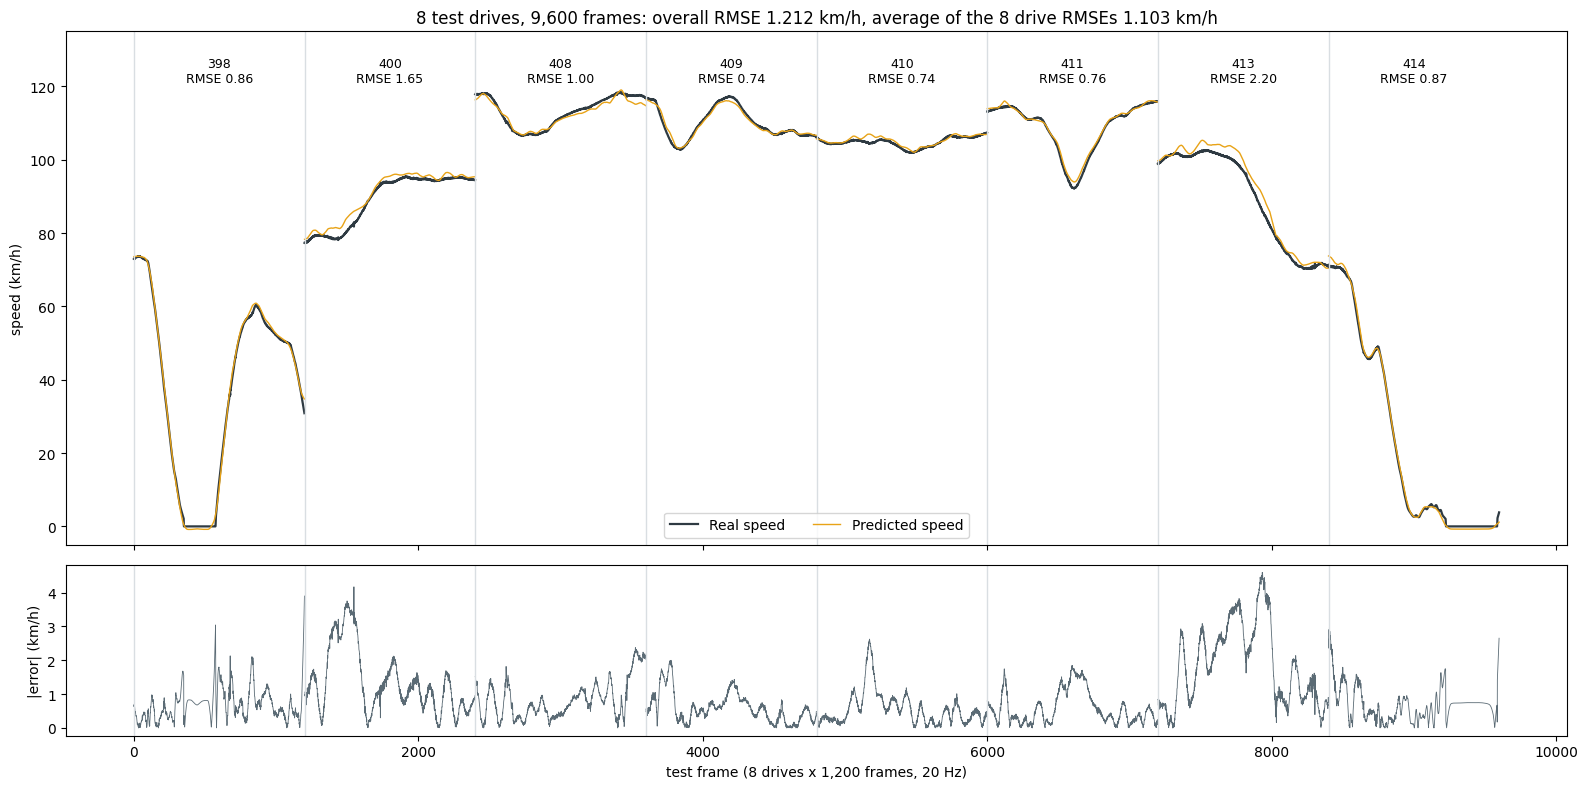

                         rmse   bias
set_id                              
Testing_Comma_2k19_398  0.863  0.157
Testing_Comma_2k19_400  1.648  1.356
Testing_Comma_2k19_408  0.999 -0.466
Testing_Comma_2k19_409  0.743 -0.141
Testing_Comma_2k19_410  0.743  0.482
Testing_Comma_2k19_411  0.759  0.424
Testing_Comma_2k19_413  2.203  1.814
Testing_Comma_2k19_414  0.868  0.062


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

d = pd.read_csv(os.path.join(PROJECT, 'outputs', 'test_predictions_final.csv'))
err = d.pred_final - d.true_speed
per = err.groupby(d.set_id).apply(lambda e: np.sqrt(np.mean(e ** 2)))
overall, avg8 = np.sqrt(np.mean(err ** 2)), per.mean()

fig, (ax, bx) = plt.subplots(2, 1, figsize=(16, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
for i, (sid, g) in enumerate(d.groupby('set_id', sort=False)):   # one segment per drive, drives side by side
    lo, hi = g.index.min(), g.index.max()
    ax.plot(g.index, g.true_speed, color='#2E3A42', lw=1.6, label='Real speed' if i == 0 else None)
    ax.plot(g.index, g.pred_final, color='#E8A317', lw=1.0, label='Predicted speed' if i == 0 else None)
    bx.plot(g.index, err[g.index].abs(), color='#5B6B75', lw=0.6)
    for a in (ax, bx):
        a.axvline(lo, color='#D9DEE2', lw=1)
    ax.text((lo + hi) / 2, 128, f'{sid.split("_")[-1]}\nRMSE {per[sid]:.2f}', ha='center', va='top', fontsize=9)
ax.set_ylim(-5, 135); ax.set_ylabel('speed (km/h)'); ax.legend(loc='lower center', ncol=2)
ax.set_title(f'8 test drives, {len(d):,} frames: overall RMSE {overall:.3f} km/h, average of the 8 drive RMSEs {avg8:.3f} km/h')
bx.set_ylabel('|error| (km/h)'); bx.set_xlabel('test frame (8 drives x 1,200 frames, 20 Hz)')
plt.tight_layout(); plt.show()
print(pd.DataFrame({'rmse': per, 'bias': err.groupby(d.set_id).mean()}).round(3).to_string())

## 7. Test evaluations during development
The test set was evaluated 13 times. Each configuration was fixed from CV before its test run, except the last choice:
the same model with 4 instead of 2 all-data front-view seeds (test #13, 1.215 / 1.106 km/h) was compared after both were
seen, and the 2-seed version (test #12) was submitted.

| # | Change | Overall RMSE (km/h) |
|---|---|---|
| 1 | ResNet-18, 4 front-camera frames, 3 seeds | 4.94 |
| 2 | + frame-difference channels, calibration + EMA smoothing | 5.11 |
| 3 | Top-down ConvNeXt-Tiny (17 frames) + optical-flow gate, centred smoothing | 2.82 |
| 4 | + speed augmentation | 2.53 |
| 5 | + model trained on all 68 drives, OOF bias offset | 1.96 |
| 6 | + zoom variant (SZ), more seeds | 1.85 |
| 7 | 6 all-data top-down models | 1.84 |
| 8 | + front-view branch (ConvNeXt-Tiny) | 1.54 |
| 9 | + temporal test-time augmentation | 1.515 |
| 10 | 4 front-view seeds | 1.508 |
| 11 | front view on ConvNeXt-Nano (ImageNet-12k), 8 epochs | 1.267 |
| **12** | **front view trained 15 epochs, soft blend (submitted)** | **1.212** |
| 13 | test #12 with 4 front-view seeds | 1.215 |